# CSE558 Data Science Midterm Project (DataMindz)
## What Changes a Mind? Length, Timing and Links on r/ChangeMyView

**Raw archive coverage:** January 2013 through December 2025  
**Analysis window:** posts created from 1 April 2017 through 30 November 2022

- `changemyview_submissions.zst`: 345,098 posts
- `changemyview_comments.zst`: 18,644,355 comments (about 4.2 GB compressed)

This notebook reconstructs delta outcomes, prepares the reply- and thread-level analysis tables, produces the report figures, and runs four hypothesis tests. The full comments archive is streamed once, so runtime and memory use depend on the machine.

## 0. Setup

The setup cell imports the required packages, locates the raw archives relative to the project root, defines the analysis window, and creates the report-figure directory.

In [1]:
# pip install zstandard orjson pandas numpy scipy matplotlib
import io, re, time
from array import array
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import orjson, zstandard
import matplotlib.pyplot as plt
from scipy import stats

ROOT = Path.cwd()
if (
    not (ROOT / "data" / "raw").is_dir()
    and (ROOT / "CSE558_CMV_FINAL" / "data" / "raw").is_dir()
):
    ROOT = ROOT / "CSE558_CMV_FINAL"
DATA_DIR = ROOT / "data" / "raw"  # original archives, kept locally
SUB_FILE = DATA_DIR / "changemyview_submissions.zst"
COM_FILE = DATA_DIR / "changemyview_comments.zst"
FIG_DIR = ROOT / "report" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

WINDOW = ("2017-04-01", "2022-12-01")  # posts created in [start, end): see Section 3.2
ALPHA = 0.05
plt.rcParams.update(
    {"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False}
)
pd.set_option("display.width", 160)
for archive in (SUB_FILE, COM_FILE):
    if not archive.is_file():
        raise FileNotFoundError(f"Missing raw archive: {archive}")


In [2]:
REMOVED = {"[deleted]", "[removed]", ""}
WORD_RE = re.compile(r"\S+")
URL_RE = re.compile(r"https?://|www\.", re.I)
CONFIRM_RE = re.compile(r"confirmed\W+1 delta awarded", re.I)
B36 = "0123456789abcdefghijklmnopqrstuvwxyz"


def to36(n):
    s = ""
    while n:
        n, r = divmod(n, 36)
        s = B36[r] + s
    return s or "0"


def stream(path):
    # read a .zst JSON-lines dump one record at a time; nothing is loaded whole
    with open(path, "rb") as fh:
        reader = zstandard.ZstdDecompressor(max_window_size=2**31).stream_reader(fh)
        for line in io.TextIOWrapper(reader, encoding="utf-8", errors="replace"):
            if line.strip():
                try:
                    yield orjson.loads(line)
                except orjson.JSONDecodeError:
                    continue


def is_bot(name):
    name = name.lower()
    return name.endswith("bot") or name in {"automoderator", "deltabot"}


---
## 1. Dataset overview

### 1.1 Source and interpretation
[r/ChangeMyView](https://www.reddit.com/r/changemyview/) is a discussion community where an original poster (OP) states a view and other users respond. An OP may award a delta ($\Delta$) when a response changes their view, and DeltaBot records that award in a confirmation comment. The delta is an observed public acknowledgement of persuasion; it does not capture unreported changes of mind.

The compressed per-subreddit archives were obtained through the [Arctic Shift Reddit Download Tool](https://arctic-shift.photon-reddit.com/download-tool). Each line is one JSON object. The notebook streams the complete files and retains only fields needed for filtering, outcome reconstruction, descriptive analysis, and testing.

### 1.2 Submissions

This pass reads all 345,098 archived submissions and retains post ID, OP name, creation time, NSFW status, title, whitespace-token count, removal status, and removal category.

In [3]:
t0 = time.time()
sub_fields, rows = set(), []
for d in stream(SUB_FILE):
    sub_fields.update(d.keys())
    pid = d.get("id")
    if not pid:
        continue
    text, author = (d.get("selftext") or "").strip(), d.get("author") or ""
    rows.append(
        (
            int(pid, 36),
            author,
            int(float(d.get("created_utc") or 0)),
            bool(d.get("over_18")),
            (d.get("title") or "").strip(),
            len(WORD_RE.findall(text)),
            text in REMOVED or author in REMOVED,
            d.get("removed_by_category") or "",
        )
    )
posts = pd.DataFrame(
    rows,
    columns=[
        "pid",
        "op",
        "created",
        "nsfw",
        "title",
        "post_words",
        "post_removed",
        "removed_by",
    ],
)
del rows
print(
    f"Submissions: {len(posts):,} rows, {len(sub_fields)} distinct fields across the file ({time.time()-t0:.0f}s)"
)
print(
    "Date range:",
    pd.to_datetime(posts.created.min(), unit="s").date(),
    "to",
    pd.to_datetime(posts.created.max(), unit="s").date(),
)


Submissions: 345,098 rows, 132 distinct fields across the file (27s)
Date range: 2013-01-17 to 2025-12-31


### 1.3 Comments

The notebook streams all 18.6 million comments. For every usable comment it retains identifiers, creation time, an author hash, and flags needed to identify OP messages and removed text. For top-level replies it also records whitespace-token count, URL presence, and bot or moderator status. Integer IDs appearing in later archive records are normalized to the same numeric representation as earlier base-36 IDs.

In [4]:
op_of = dict(zip(posts.pid.values, posts.op.values))
cid, parent, parent_is_c, link, created = (
    array("q"),
    array("q"),
    array("b"),
    array("q"),
    array("q"),
)
author_h, is_op, removed = array("q"), array("b"), array("b")
top = []  # (id, author, words, has_link, bot_or_mod)
confirm_parent = (
    []
)  # comments DeltaBot confirmed a delta on (these are the OP's award messages)
com_fields, n = set(), 0

for d in stream(COM_FILE):
    n += 1
    if n % 100 == 0:
        com_fields.update(d.keys())
    if n % 3_000_000 == 0:
        print(f"  {n:,} comments ({time.time()-t0:.0f}s)")
    i, p, l = d.get("id"), d.get("parent_id"), d.get("link_id")
    if isinstance(l, int):
        l = "t3_" + to36(l)
    if isinstance(p, int):
        p = ("t3_" if l and p == int(l[3:], 36) else "t1_") + to36(p)
    if isinstance(i, int):
        i = to36(i)
    if not i or not p or not l:
        continue
    a, body = d.get("author") or "", d.get("body") or ""
    gone = body.strip() in REMOVED or a in REMOVED
    ci, lid, reply_to_comment = int(i, 36), int(l[3:], 36), p.startswith("t1_")
    if a == "DeltaBot" and reply_to_comment and CONFIRM_RE.search(body):
        confirm_parent.append(int(p[3:], 36))
    cid.append(ci)
    parent.append(int(p[3:], 36))
    parent_is_c.append(reply_to_comment)
    link.append(lid)
    created.append(int(float(d.get("created_utc") or 0)))
    author_h.append(0 if a in REMOVED else hash(a))
    is_op.append(a not in REMOVED and op_of.get(lid) == a)
    removed.append(gone)
    if not reply_to_comment:
        top.append(
            (
                ci,
                a,
                0 if gone else len(WORD_RE.findall(body)),
                bool(URL_RE.search(body)) and not gone,
                is_bot(a) or d.get("distinguished") == "moderator",
            )
        )

E = pd.DataFrame(
    {
        "id": np.frombuffer(cid, np.int64),
        "parent": np.frombuffer(parent, np.int64),
        "parent_is_c": np.frombuffer(parent_is_c, np.int8).astype(bool),
        "link": np.frombuffer(link, np.int64),
        "created": np.frombuffer(created, np.int64),
        "author_h": np.frombuffer(author_h, np.int64),
        "is_op": np.frombuffer(is_op, np.int8).astype(bool),
        "removed": np.frombuffer(removed, np.int8).astype(bool),
    }
)
TOP = pd.DataFrame(
    top, columns=["id", "author", "words", "has_link", "bot_or_mod"]
).drop_duplicates("id")
del cid, parent, parent_is_c, link, created, author_h, is_op, removed, top
print(
    f"Comments: {n:,} rows, {len(com_fields)} distinct fields ({time.time()-t0:.0f}s)"
)


  3,000,000 comments (156s)


  6,000,000 comments (265s)


  9,000,000 comments (367s)


  12,000,000 comments (503s)


  15,000,000 comments (625s)


  18,000,000 comments (778s)


Comments: 18,644,355 rows, 81 distinct fields (811s)


---
## 2. Raw data inspection

This section checks date coverage, schema variation, duplicated comment IDs, missing or removed text, and yearly record counts before applying analytical filters.

In [5]:
print("A few raw posts:")
display(
    posts.assign(
        id=posts.pid.map(to36), date=pd.to_datetime(posts.created, unit="s").dt.date
    )[["id", "date", "title", "post_words", "nsfw", "post_removed"]].head(3)
)
n_dup = int(E.duplicated("id").sum())
E = E.drop_duplicates("id").reset_index(drop=True)
print(f"Duplicate comment IDs: {n_dup:,} (dropped, first copy kept)")
print(f"Post text removed or deleted: {posts.post_removed.mean():.1%} of all posts")
print(
    "Why posts were removed (only recorded from 2019):",
    posts.removed_by.replace("", "not recorded").value_counts().head(4).to_dict(),
)
yr = pd.to_datetime(posts.created, unit="s").dt.year
display(
    pd.DataFrame(
        {
            "posts": posts.groupby(yr).size(),
            "comments": E.groupby(pd.to_datetime(E.created, unit="s").dt.year).size(),
        }
    ).T
)


A few raw posts:


,id,date,title,post_words,nsfw,post_removed
0,16s77g,2013-01-17,I feel that becoming successful as a musician ...,75,False,False
1,16s6sq,2013-01-17,I think all language is inherently metaphorica...,40,False,False
2,16s6jg,2013-01-17,"The town of Oxford Hills is a shithole, CMV pl...",39,False,False


Duplicate comment IDs: 2,508 (dropped, first copy kept)
Post text removed or deleted: 65.8% of all posts
Why posts were removed (only recorded from 2019): {'not recorded': 215272, 'moderator': 80039, 'deleted': 40979, 'reddit': 7853}


created,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025
posts,16952,19955,16422,16587,21366,32289,30861,42258,33844,24753,22976,28601,38234
comments,670553,895894,704759,706898,906645,1220052,1155716,1678445,1955693,1564463,1714767,2441547,3026415


---
## 3. Data preparation

### 3.1 Reconstructing the reply-level outcome
The archive has no ready-made delta outcome column. A delta character alone is unreliable because it can occur in quotations, rules, or bot text. The reconstruction therefore follows DeltaBot confirmations:

1. Find a DeltaBot confirmation that replies to an award message $m$.
2. Require $m$ to be written by the thread's OP and to reply to an awarded comment $x$.
3. Walk $x$ upward to the top-level reply $r$ that opened the branch.
4. Label $r$ as `won = 1` when $x=r$, or when $x$ and $r$ have the same non-deleted author. Awards to another author later in the branch are not credited to the opener.

This creates a binary outcome for eligible top-level replies while retaining the reply tree needed to handle later awards by the opening author.

In [6]:
idx = pd.Index(E.id.values)
conf = np.unique(np.array(confirm_parent, dtype=np.int64))
pos = idx.get_indexer(conf)
msg = E.iloc[pos[pos >= 0]]
chain = {
    "DeltaBot confirmations": len(confirm_parent),
    "confirmed message found in archive": len(msg),
}
msg = msg[msg.is_op & msg.parent_is_c]
chain["written by the OP, replying to a comment"] = len(msg)
awarded = np.unique(msg.parent.values)
chain["awarded comments"] = len(awarded)
awarding_posts = set(msg.link.values)  # threads where the OP gave at least one delta

# walk every awarded comment up to the top-level reply that opened its branch
root = awarded.copy()
for _ in range(1000):
    p = idx.get_indexer(root)
    deeper = np.zeros(len(root), bool)
    deeper[p >= 0] = E.parent_is_c.values[p[p >= 0]]
    if not deeper.any():
        break
    root[deeper] = E.parent.values[p[deeper]]
a_auth = E.author_h.values[idx.get_indexer(awarded)]
r_pos = idx.get_indexer(root)
r_auth = np.where(r_pos >= 0, E.author_h.values[r_pos], -1)
direct = awarded == root
same_author = ~direct & (a_auth == r_auth) & (a_auth != 0)
won_openers = set(root[direct | same_author])
chain["... on the top-level reply itself"] = int(direct.sum())
chain["... later in the branch, by the opener's author"] = int(same_author.sum())
chain["... later in the branch, by someone else (not counted)"] = int(
    (~direct & ~same_author).sum()
)
chain["top-level replies that won"] = len(won_openers)
pd.Series(chain).to_frame("count").style.format("{:,}")


,count
DeltaBot confirmations,"137,226"
confirmed message found in archive,"136,573"
"written by the OP, replying to a comment","101,376"
awarded comments,"101,306"
... on the top-level reply itself,"57,031"
"... later in the branch, by the opener's author","26,573"
"... later in the branch, by someone else (not counted)","17,702"
top-level replies that won,"82,545"


The branch walk identifies 26,573 awards made later in a discussion to another comment by the opening reply's author. Direct-award matching alone would miss these outcomes.

### 3.2 Choosing the analysis window
The raw files span January 2013 through December 2025, but the analysis uses posts from 1 April 2017 through 30 November 2022. The selected interval has more consistent bot-based award capture and avoids the sharp archive discontinuity visible after 2022. The quarterly OP-award share is inspected as a measurement-stability diagnostic, not as proof that every other community condition is unchanged.

In [7]:
posts["intact"] = ~posts.post_removed
posts["op_awarded"] = posts.pid.isin(awarding_posts)
posts["is_cmv"] = posts.title.str.match(r"(?i)^\s*cmv")
events = posts[
    posts.title.str.contains(
        r"(?i)deltabot|delta ?log|chatgpt|ai-generated|unauthorized experiment"
    )
    & posts.title.str.contains(r"(?i)mod post|meta")
]
display(
    events.assign(date=pd.to_datetime(events.created, unit="s").dt.date)[
        ["date", "title"]
    ]
    .sort_values("date")
    .reset_index(drop=True)
    .style.hide(axis="index")
)


date,title
2013-02-25,"[MOD POST] New ""delta points"" system and /u/DeltaBot. Let us know what you think."
2013-05-05,"[MOD POST] DeltaBot crashed during the huge rise in traffic, please link me to any missed deltas you know of."
2013-06-22,[MOD POST] We are looking for someone to be the programmer of DeltaBot!
2013-08-28,[MOD POST] A discussion of TCMV Tuesdays/Deltas and a continued search for DeltaBot Programmers/Wiki Contributors!
2013-09-18,[Mod Post] DeltaBot programmers needed! (Link to the code inside)
2014-05-15,"[Mod Post] Follow us on twitter @redditcmv for a live feed of new CMV posts. Also, DeltaBot is playing up."
2015-03-10,[Mod Post] Announcement: DeltaBot needs your help!
2015-04-30,[Mod Post] A call for help to fix and finish our DeltaBot.
2015-05-13,[Mod Post] DeltaBot is (still) down
2015-06-24,"[Meta] Deltabot is down, but your Deltas are being saved!"


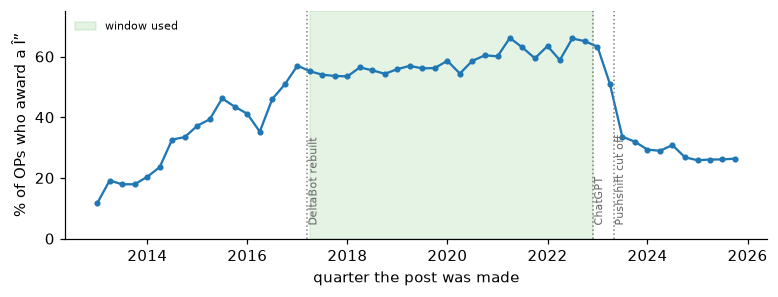

Inside the window the share stays between 53% and 66% every quarter.
Takeaway: before 2017 the share climbs while DeltaBot keeps missing deltas; after mid-2023 it halves when the archive changes hands. Between them it is flat.


In [ ]:
q = pd.to_datetime(posts.created, unit="s").dt.to_period("Q")
share = posts[posts.intact & posts.is_cmv].groupby(q).op_awarded.mean()
x = share.index.to_timestamp()
fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.axvspan(
    pd.Timestamp(WINDOW[0]),
    pd.Timestamp(WINDOW[1]),
    color="tab:green",
    alpha=0.12,
    label="window used",
)
ax.plot(x, 100 * share.values, marker="o", ms=3, color="tab:blue")
for d, lab in [
    ("2017-03-15", "DeltaBot rebuilt"),
    ("2022-11-30", "ChatGPT"),
    ("2023-05-01", "Pushshift cut off"),
]:
    ax.axvline(pd.Timestamp(d), color="grey", ls=":", lw=1)
    ax.text(
        pd.Timestamp(d),
        3,
        " " + lab,
        rotation=90,
        fontsize=7,
        color="dimgrey",
        va="bottom",
    )
ax.set_ylim(0, 75)
ax.set_ylabel("% of OPs who award a  ")
ax.set_xlabel("quarter the post was made")
ax.legend(loc="upper left", fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "op_award_share.png", dpi=220)
plt.show()
w = share[(x >= WINDOW[0]) & (x < WINDOW[1])]
print(
    f"Inside the window the share stays between {w.min():.0%} and {w.max():.0%} every quarter."
)
print(
    "Takeaway: before 2017 the share climbs while DeltaBot keeps missing deltas; after mid-2023 it halves when the archive changes hands. Between them it is flat."
)


**Analysis window: 1 April 2017 through 30 November 2022.**

- The start excludes earlier years in which bot-based award capture is visibly less stable.
- The end precedes the large post-2022 discontinuity in the archived series.
- Every descriptive statistic and hypothesis test below uses this filtered window. References to 2013-2025 describe only the raw archive coverage.

### 3.3 Thread eligibility

In [9]:
start, end = (pd.Timestamp(s).timestamp() for s in WINDOW)
funnel = [("All posts", len(posts))]
P = posts[(posts.created >= start) & (posts.created < end)]
funnel.append(("posted inside the window", len(P)))
P = P[P.is_cmv]
funnel.append(('title starts with "CMV" (drops mod/meta posts)', len(P)))
P = P[~P.nsfw]
funnel.append(("not marked NSFW", len(P)))
removed_threads = P[~P.intact]
P = P[P.intact]
funnel.append(("post text and OP account intact", len(P)))
THREADS = P.copy()  # used for Test 4
P = P[P.op_awarded]
funnel.append(("OP awarded at least one delta", len(P)))
display(
    pd.DataFrame(funnel, columns=["step", "posts"])
    .style.format({"posts": "{:,}"})
    .hide(axis="index")
)

n_top = E[~E.parent_is_c].groupby("link").size()
rt = removed_threads.pid.map(n_top).fillna(0)
print(
    f"Removed threads: median {rt.median():.0f} top-level replies, {(rt <= 2).mean():.0%} have 2 or fewer; "
    f"an OP delta appears in {removed_threads.op_awarded.mean():.1%} of them vs {THREADS.op_awarded.mean():.1%} of intact threads."
)


step,posts
All posts,"345,098"
posted inside the window,"178,554"
"title starts with ""CMV"" (drops mod/meta posts)","155,890"
not marked NSFW,"154,564"
post text and OP account intact,"44,160"
OP awarded at least one delta,"25,447"


Removed threads: median 1 top-level replies, 59% have 2 or fewer; an OP delta appears in 1.2% of them vs 57.6% of intact threads.


- **CMV title:** retain titles beginning with `CMV`, which excludes moderator announcements and meta posts.
- **NSFW:** exclude these threads because restricted visibility creates a different exposure process.
- **Intact post and OP identity:** require usable post text and a known OP. Neither argument text nor authorship can be validly imputed.
- **OP award requirement:** Tests 1-3 retain threads with at least one observed OP delta because those tests require positive and negative reply outcomes. Test 4 uses all intact eligible threads and compares award with non-award threads. Conditioning Tests 1-3 on awarding threads limits how broadly their results can be generalized.

### 3.4 Reply eligibility

In [10]:
pc = P.set_index("pid")
R = E[~E.parent_is_c & E.link.isin(pc.index)].merge(TOP, on="id", how="left")
steps = [
    ("deleted or removed reply", R.removed),
    ("OP's own top-level comment", R.is_op),
    ("bot or moderator notice", R.bot_or_mod.fillna(False).astype(bool)),
    ("fewer than 10 words", R.words < 10),
]
funnel2, keep = [("Top-level replies in kept threads", len(R))], pd.Series(
    True, index=R.index
)
for name, m in steps:
    m = m & keep
    funnel2.append(("  minus " + name, int(m.sum())))
    keep &= ~m
A = R[keep].copy()
A["won"] = A.id.isin(won_openers).astype(int)
A["post_created"] = A.link.map(pc.created)
A["delay_h"] = (A.created - A.post_created) / 3600
A["post_words"] = A.link.map(pc.post_words)
A["year"] = pd.to_datetime(A.post_created, unit="s").dt.year
A = A[
    ["id", "link", "year", "words", "delay_h", "has_link", "post_words", "won"]
].reset_index(drop=True)
funnel2 += [("Replies analysed", len(A)), ("  of which won a delta", int(A.won.sum()))]
display(
    pd.DataFrame(funnel2, columns=["step", "replies"])
    .style.format({"replies": "{:,}"})
    .hide(axis="index")
)
print(
    f"Replies arriving before their post: {(A.delay_h < 0).sum()}; threads: {A.link.nunique():,}"
)


step,replies
Top-level replies in kept threads,"612,211"
minus deleted or removed reply,"83,114"
minus OP's own top-level comment,166
minus bot or moderator notice,"29,204"
minus fewer than 10 words,"20,451"
Replies analysed,"479,276"
of which won a delta,"42,197"


Replies arriving before their post: 0; threads: 25,439


- **Deleted or removed replies:** exclude them because reply length cannot be measured.
- **OP-authored top-level comments, bots, and moderator notices:** exclude them because they are not independent attempts to change the OP's view.
- **Replies below 10 whitespace-separated tokens:** exclude them as a substantive-reply eligibility rule. This removes 20,451 replies, or 4.1% of otherwise eligible replies. The cutoff is a modeling choice; a sensitivity analysis at 0, 5, and 10 tokens would be needed to show that conclusions are insensitive to it.
- **Score:** do not filter on score, so unpopular replies remain eligible.

### 3.5 Outliers and transformations

C:\Users\Acer\AppData\Local\Temp\vscode-agent-codex-sandbox-IC6Uj8\ipykernel_14952\2696579110.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[0, j].boxplot(v, vert=False, flierprops={'markersize': 1, 'alpha': .2}); ax[0, j].set_title(k + ' (raw)', fontsize=9)
C:\Users\Acer\AppData\Local\Temp\vscode-agent-codex-sandbox-IC6Uj8\ipykernel_14952\2696579110.py:11: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax[1, j].boxplot(np.log1p(v), vert=False, flierprops={'markersize': 1, 'alpha': .2}); ax[1, j].set_title(f'log(1 + {k})', fontsize=9)
C:\Users\Acer\AppData\Local\Temp\vscode-agent-codex-sandbox-IC6Uj8\ipykernel_14952\2696579110.py:10: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'v

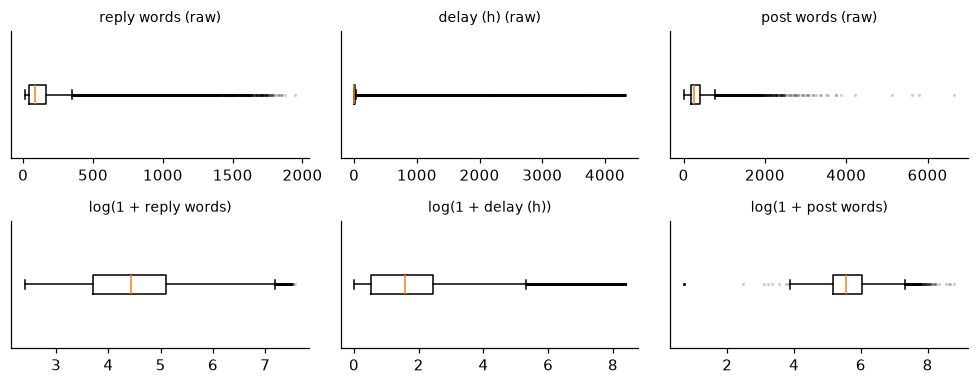

Takeaway: lengths are right-skewed with 6-9% of points past the fence; after log(1+x) skew is near 0 and few points remain outside.


In [11]:
def shape(x):
    q1, q3 = np.percentile(x, [25, 75])
    fence = q3 + 1.5 * (q3 - q1)
    return {
        "median": np.median(x),
        "Q3": q3,
        "upper fence": fence,
        "% beyond fences": np.mean((x > fence) | (x < q1 - 1.5 * (q3 - q1))),
        "skewness": stats.skew(x),
        "max": np.max(x),
    }


cols = {
    "reply words": A.words,
    "delay (h)": A.delay_h,
    "post words": THREADS.post_words,
}
O = pd.DataFrame(
    {
        (k, f): shape(f_(v.values))
        for k, v in cols.items()
        for f, f_ in [("raw", lambda z: z), ("log(1+x)", np.log1p)]
    }
).T
display(
    O.style.format(
        {
            "median": "{:.2f}",
            "Q3": "{:.2f}",
            "upper fence": "{:.2f}",
            "% beyond fences": "{:.1%}",
            "skewness": "{:.2f}",
            "max": "{:,.1f}",
        }
    )
)
fig, ax = plt.subplots(2, 3, figsize=(9, 3.6))
for j, (k, v) in enumerate(cols.items()):
    ax[0, j].boxplot(v, vert=False, flierprops={"markersize": 1, "alpha": 0.2})
    ax[0, j].set_title(k + " (raw)", fontsize=9)
    ax[1, j].boxplot(
        np.log1p(v), vert=False, flierprops={"markersize": 1, "alpha": 0.2}
    )
    ax[1, j].set_title(f"log(1 + {k})", fontsize=9)
    for a in ax[:, j]:
        a.set_yticks([])
fig.tight_layout()
fig.savefig(FIG_DIR / "outliers_boxplots.png", dpi=200)
plt.show()
print(
    "Takeaway: lengths are right-skewed with 6-9% of points past the fence; after log(1+x) skew is near 0 and few points remain outside."
)


Long posts and replies are retained because they are plausible observations rather than measurement errors. Length variables are analyzed using `log(1+x)`, which reduces right skew and makes mean differences interpretable approximately as ratios. Response delay remains highly skewed; descriptive summaries use medians, while timing tests use prespecified delay groups rather than a raw-delay mean comparison.

### 3.6 Encoding and size check
`has_link` is a binary indicator for text containing `http://`, `https://`, or `www.`; it does not validate the destination as evidence. Delay is represented by five one-hot indicators: `<1h`, `1-3h`, `3-6h`, `6-24h`, and `>24h`. The 11-column reply table also retains raw delay, length variables, post length, and the binary outcome.

In [ ]:
DELAY_BINS, DELAY_LABELS = [-np.inf, 1, 3, 6, 24, np.inf], [
    "<1h",
    "1-3h",
    "3-6h",
    "6-24h",
    ">24h",
]
A["delay_bin"] = pd.cut(A.delay_h, DELAY_BINS, labels=DELAY_LABELS)
A["log_words"] = np.log1p(A.words)
X = pd.concat(
    [
        A[["words", "log_words", "delay_h", "has_link", "post_words", "won"]].astype(
            float
        ),
        pd.get_dummies(A.delay_bin, prefix="delay", dtype=float),
    ],
    axis=1,
)
print(
    f"Encoded table: {X.shape[0]:,} replies x {X.shape[1]} attributes = {X.shape[0] * X.shape[1]:,}  (>= 3,000,000: {X.size >= 3_000_000})"
)
print("Attributes:", list(X.columns))


Encoded table: 479,276 replies x 11 attributes = 5,272,036  (>= 3,000,000: True)
Attributes: ['words', 'log_words', 'delay_h', 'has_link', 'post_words', 'won', 'delay_<1h', 'delay_1-3h', 'delay_3-6h', 'delay_6-24h', 'delay_>24h']


---
## 4. Before and after preparation

The table below distinguishes raw archive coverage from the filtered analytical datasets. Tests 1-3 operate on retained top-level replies; Test 4 operates on intact eligible threads.

In [ ]:
pd.DataFrame(
    {
        "measure": [
            "rows",
            "fields",
            "time span",
            "duplicate comment IDs",
            "missing or unusable text",
            "outcome column",
            "ID format",
        ],
        "before (raw)": [
            f"{len(posts):,} posts, {n:,} comments",
            f"{len(sub_fields)} post / {len(com_fields)} comment",
            "2013-01 to 2025-12",
            f"{n_dup:,}",
            f"{posts.post_removed.mean():.0%} of posts, {E.removed.mean():.0%} of comments",
            "none (  only inside text)",
            "base-36 strings, base-10 ints after 2023",
        ],
        "after": [
            f"{len(A):,} replies in {A.link.nunique():,} threads",
            f"{X.shape[1]} encoded",
            "2017-04 to 2022-11",
            "0",
            "0",
            f"won (0/1): {int(A.won.sum()):,} winners",
            "one integer ID",
        ],
    }
).style.hide(axis="index")


measure,before (raw),after
rows,"345,098 posts, 18,644,355 comments","479,276 replies in 25,439 threads"
fields,132 post / 81 comment,11 encoded
time span,2013-01 to 2025-12,2017-04 to 2022-11
duplicate comment IDs,"2,508",0
missing or unusable text,"66% of posts, 8% of comments",0
outcome column,none (ÃŽâ€ only inside text),"won (0/1): 42,197 winners"
ID format,"base-36 strings, base-10 ints after 2023",one integer ID


---
## 5. Exploratory data analysis

The exploratory section answers three descriptive questions:

1. What are the typical reply length and response delay, and how often does a reply contain a URL?
2. What share of intact eligible threads contains at least one OP delta?
3. Among retained replies in awarding threads, what share receives the reconstructed winning label?

These summaries describe associations in the selected window and do not establish causal effects.

In [14]:
print(
    f"Replies: median {A.words.median():.0f} words (IQR {A.words.quantile(.25):.0f}-{A.words.quantile(.75):.0f}); "
    f"median delay {A.delay_h.median():.1f} h; {A.has_link.mean():.1%} contain a link."
)
print(
    f"OPs who award a delta: {THREADS.op_awarded.mean():.1%} of {len(THREADS):,} intact threads."
)
per = A.groupby("link").won.agg(["sum", "size"])
print(
    f'Awarding threads: median {per["size"].median():.0f} replies and {per["sum"].median():.0f} winner; overall {A.won.mean():.1%} of replies win.'
)
by_year = A.groupby("year").agg(
    replies=("won", "size"),
    win_rate=("won", "mean"),
    replies_per_thread=("link", lambda s: len(s) / s.nunique()),
)
by_year["OPs who award"] = THREADS.groupby(
    pd.to_datetime(THREADS.created, unit="s").dt.year
).op_awarded.mean()
display(
    by_year.style.format(
        {
            "replies": "{:,}",
            "win_rate": "{:.1%}",
            "replies_per_thread": "{:.1f}",
            "OPs who award": "{:.1%}",
        }
    )
)
print(
    "Takeaway: threads got bigger every year, so the win rate per reply falls, while the share of OPs who award stays level."
)


Replies: median 84 words (IQR 40-163); median delay 3.8 h; 6.2% contain a link.
OPs who award a delta: 57.6% of 44,160 intact threads.


Awarding threads: median 12 replies and 1 winner; overall 8.8% of replies win.


,replies,win_rate,replies_per_thread,OPs who award
year,,,,
2017,"44,430",12.3%,12.8,54.2%
2018,"80,072",10.9%,14.7,54.9%
2019,"68,645",9.5%,16.6,56.2%
2020,"97,367",8.7%,19.7,57.7%
2021,"109,245",7.2%,24.2,62.3%
2022,"79,517",6.5%,27.1,63.2%


Takeaway: threads got bigger every year, so the win rate per reply falls, while the share of OPs who award stays level.


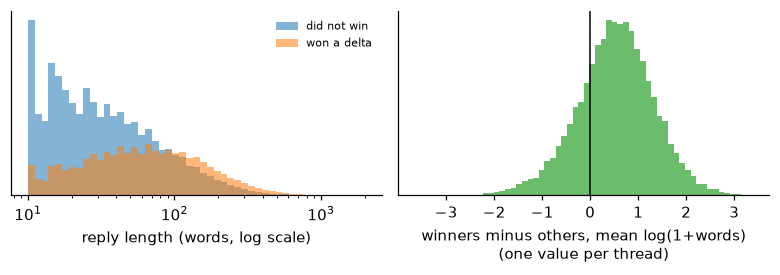

Takeaway: winning replies are longer, and inside the same thread the winners are longer in 76% of threads.


In [15]:
g = A.groupby(["link", "won"]).log_words.mean().unstack().dropna()
d_len = g[1] - g[0]
fig, ax = plt.subplots(1, 2, figsize=(7.2, 2.6))
bins = np.logspace(1, np.log10(2000), 50)
for k, lab, c in [(0, "did not win", "tab:blue"), (1, "won a delta", "tab:orange")]:
    ax[0].hist(
        A.words[A.won == k], bins=bins, density=True, alpha=0.55, label=lab, color=c
    )
ax[0].set_xscale("log")
ax[0].set_xlabel("reply length (words, log scale)")
ax[0].set_yticks([])
ax[0].legend(fontsize=7, frameon=False)
ax[1].hist(d_len, bins=60, color="tab:green", alpha=0.7)
ax[1].axvline(0, color="k", lw=1)
ax[1].set_xlabel("winners minus others, mean log(1+words)\n(one value per thread)")
ax[1].set_yticks([])
fig.tight_layout()
fig.savefig(FIG_DIR / "length.png", dpi=220)
plt.show()
print(
    f"Takeaway: winning replies are longer, and inside the same thread the winners are longer in {(d_len > 0).mean():.0%} of threads."
)


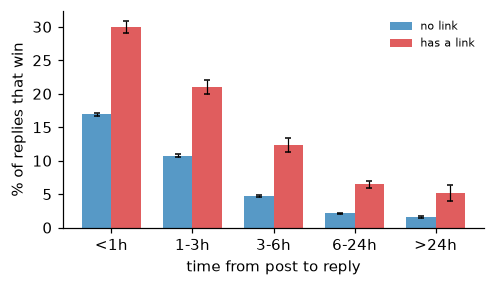

Takeaway: the win rate falls from 17.9% in the first hour to 1.8% after a day, and replies with a link win more at every delay.


In [16]:
def rate_ci(s):
    p, m = s.mean(), len(s)
    se = np.sqrt(p * (1 - p) / m)
    return pd.Series({"rate": p, "lo": p - 1.96 * se, "hi": p + 1.96 * se, "n": m})


tab = A.groupby(["delay_bin", "has_link"], observed=True).won.apply(rate_ci).unstack()
fig, ax = plt.subplots(figsize=(4.6, 2.7))
xs = np.arange(len(DELAY_LABELS))
for off, hl, lab, c in [
    (-0.18, False, "no link", "tab:blue"),
    (0.18, True, "has a link", "tab:red"),
]:
    t = tab.xs(hl, level="has_link")
    ax.bar(
        xs + off,
        100 * t.rate,
        width=0.36,
        color=c,
        alpha=0.75,
        label=lab,
        yerr=[100 * (t.rate - t.lo), 100 * (t.hi - t.rate)],
        capsize=2,
        error_kw={"lw": 0.8},
    )
ax.set_xticks(xs, DELAY_LABELS)
ax.set_xlabel("time from post to reply")
ax.set_ylabel("% of replies that win")
ax.legend(fontsize=7, frameon=False)
fig.tight_layout()
fig.savefig(FIG_DIR / "delay_link.png", dpi=220)
plt.show()
r = A.groupby("delay_bin", observed=True).won.mean()
print(
    f"Takeaway: the win rate falls from {r.iloc[0]:.1%} in the first hour to {r.iloc[-1]:.1%} after a day, and replies with a link win more at every delay."
)


### Analytical questions
- **P1 (primary):** Within the same thread, are winning replies longer than other retained replies?
- **P2:** Is the observed win rate higher for replies posted within 3 hours than for later replies?
- **P3:** Is the observed win rate higher for replies containing a URL than for replies without one?
- **P4:** Do OPs who award at least one delta write longer original posts, on average, than OPs who do not?

P1 uses a within-thread comparison. P2 and P3 compare reply-level proportions, while P4 changes the unit of analysis to one intact thread.

---
## 6. Hypothesis testing

Each section states the null and alternative hypotheses, significance level, test direction, selected test, and a practical-effect threshold before displaying the computed result. The notebook implements the statistics directly and checks them against `scipy` functions.

**Practical-effect thresholds:** length comparisons use a ratio of 1.20; win-rate comparisons use 2 percentage points, approximately 20% of the 8.8% reply-level base rate. Statistical significance and practical magnitude are interpreted separately.

In [17]:
def fmt_p(p):
    return "< 1e-300" if p < 1e-300 else f"{p:.2e}"


def paired_t(d):  # Lecture 7: t = dbar / (s_d / sqrt(n)), df = n - 1
    n, dbar, s = len(d), d.mean(), d.std(ddof=1)
    se = s / np.sqrt(n)
    df = n - 1
    tc = stats.t.ppf(0.975, df)
    return {
        "n": n,
        "est": dbar,
        "se": se,
        "t": dbar / se,
        "df": df,
        "ci": (dbar - tc * se, dbar + tc * se),
    }


def welch_t(x, y):  # unequal variances, Welch-Satterthwaite df
    vx, vy, nx, ny = x.var(ddof=1), y.var(ddof=1), len(x), len(y)
    se = np.sqrt(vx / nx + vy / ny)
    df = se**4 / ((vx / nx) ** 2 / (nx - 1) + (vy / ny) ** 2 / (ny - 1))
    est = x.mean() - y.mean()
    tc = stats.t.ppf(0.975, df)
    return {
        "est": est,
        "se": se,
        "t": est / se,
        "df": df,
        "ci": (est - tc * se, est + tc * se),
    }


def pooled_t(x, y):  # Lecture 7: pooled s^2, df = n1 + n2 - 2
    nx, ny = len(x), len(y)
    sp2 = ((nx - 1) * x.var(ddof=1) + (ny - 1) * y.var(ddof=1)) / (nx + ny - 2)
    se = np.sqrt(sp2 * (1 / nx + 1 / ny))
    return {"t": (x.mean() - y.mean()) / se, "df": nx + ny - 2}


def f_test(x, y):  # Lecture 7/8: F = s1^2 / s2^2, two-sided
    F, d1, d2 = x.var(ddof=1) / y.var(ddof=1), len(x) - 1, len(y) - 1
    return {
        "F": F,
        "df": (d1, d2),
        "p": 2 * min(stats.f.sf(F, d1, d2), stats.f.cdf(F, d1, d2)),
    }


def two_prop_z(
    k1, n1, k2, n2
):  # Lecture 7: pooled p for the test, unpooled SE for the CI
    p1, p2, p = k1 / n1, k2 / n2, (k1 + k2) / (n1 + n2)
    z = (p1 - p2) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return {
        "p1": p1,
        "p2": p2,
        "est": p1 - p2,
        "z": z,
        "ci": (p1 - p2 - 1.96 * se, p1 - p2 + 1.96 * se),
    }


def chi2_indep(O):  # Lecture 8: E_ij = row_i * col_j / N, df = (r-1)(c-1)
    O = np.asarray(O, float)
    Ex = O.sum(1, keepdims=True) * O.sum(0, keepdims=True) / O.sum()
    chi2 = ((O - Ex) ** 2 / Ex).sum()
    df = (O.shape[0] - 1) * (O.shape[1] - 1)
    return {"chi2": chi2, "df": df, "p": stats.chi2.sf(chi2, df)}


# sanity check against scipy on a small random sample
rng = np.random.default_rng(0)
a_, b_ = rng.normal(0, 1, 300), rng.normal(0.2, 1.5, 200)
assert np.isclose(paired_t(a_[:200] - b_)["t"], stats.ttest_rel(a_[:200], b_).statistic)
assert np.isclose(
    welch_t(a_, b_)["t"], stats.ttest_ind(a_, b_, equal_var=False).statistic
)
assert np.isclose(pooled_t(a_, b_)["t"], stats.ttest_ind(a_, b_).statistic)
assert np.isclose(
    chi2_indep([[30, 70], [45, 55]])["chi2"],
    stats.chi2_contingency([[30, 70], [45, 55]], correction=False)[0],
)
print("formulas match scipy")


formulas match scipy


### Test 1 (P1): within a thread, are winning replies longer?

| Component | Specification |
|---|---|
| $H_0$ | $\mu_d \le 0$ |
| $H_1$ | $\mu_d > 0$ |
| Significance level | $\alpha=0.05$ |
| Direction | one-sided (right) |
| Test | paired t-test |
| Practical threshold | winner/non-winner length ratio $\ge 1.20$ |

For each thread containing at least one winner and one other retained reply, $d$ is the mean $\log(1+\text{words})$ among winners minus the corresponding mean among other replies. Pairing controls for shared thread context and gives one difference per thread. The large set of nearly symmetric thread-level differences supports inference on the mean difference. The result remains associational: adding words alone is not shown to cause persuasion.

In [18]:
t1 = paired_t(d_len.values)
p1 = stats.t.sf(t1["t"], t1["df"])
ratio = np.exp([t1["est"], *t1["ci"]])
print(f"threads (pairs) n = {t1['n']:,}")
print(
    f"mean d = {t1['est']:.3f} log-units  ->  winners are {ratio[0]:.2f}x as long, 95% CI [{ratio[1]:.2f}, {ratio[2]:.2f}]"
)
print(
    f"t = {t1['t']:.1f}, df = {t1['df']:,}, one-sided p = {fmt_p(p1)} -> {'reject H0' if p1 < ALPHA else 'fail to reject H0'}"
)
print(
    f"meaningful (whole CI above 1.20): {ratio[1] > 1.20};  skewness of d = {stats.skew(d_len):.2f}"
)

# other tests we considered, run for comparison: ignore the pairing and compare all winners with all others
w1, w0 = A.log_words[A.won == 1], A.log_words[A.won == 0]
ft, wt, pt = f_test(w1, w0), welch_t(w1, w0), pooled_t(w1, w0)
print(
    f"\nF-test for equal variances: F = {ft['F']:.3f}, df = ({ft['df'][0]:,}, {ft['df'][1]:,}), p = {fmt_p(ft['p'])}"
)
print(
    f"Welch t (unpaired): ratio {np.exp(wt['est']):.2f}, t = {wt['t']:.1f}, df = {wt['df']:,.0f}"
)
print(f"Pooled t (unpaired): t = {pt['t']:.1f}, df = {pt['df']:,}")


threads (pairs) n = 23,055
mean d = 0.519 log-units  ->  winners are 1.68x as long, 95% CI [1.66, 1.70]
t = 98.4, df = 23,054, one-sided p = < 1e-300 -> reject H0
meaningful (whole CI above 1.20): True;  skewness of d = -0.20

F-test for equal variances: F = 0.833, df = (42,196, 437,078), p = 8.92e-135
Welch t (unpaired): ratio 1.77, t = 126.8, df = 52,475
Pooled t (unpaired): t = 117.6, df = 479,274


### Test 2 (P2): do replies in the first 3 hours win more often?

| Component | Specification |
|---|---|
| $H_0$ | $p_{early}-p_{late} \le 0$ |
| $H_1$ | $p_{early}-p_{late} > 0$ |
| Significance level | $\alpha=0.05$ |
| Direction | one-sided (right) |
| Test | two-proportion z-test |
| Practical threshold | 2 percentage points |

$p_{early}$ and $p_{late}$ are the winning proportions for replies posted within 3 hours and after 3 hours. The cutoff is close to the median delay and creates two large groups with enough successes and failures for the normal approximation. Replies share thread context, so the notebook also reports a thread-level paired check. Timing remains observational and may reflect visibility, author effort, or reply quality.

In [19]:
early = A.delay_h <= 3
t2 = two_prop_z(A.won[early].sum(), early.sum(), A.won[~early].sum(), (~early).sum())
p2 = stats.norm.sf(t2["z"])
print(
    f"early: {early.sum():,} replies, win rate {t2['p1']:.2%};  late: {(~early).sum():,} replies, win rate {t2['p2']:.2%}"
)
print(
    f"difference = {100*t2['est']:.2f} points, 95% CI [{100*t2['ci'][0]:.2f}, {100*t2['ci'][1]:.2f}]"
)
print(
    f"z = {t2['z']:.1f}, one-sided p = {fmt_p(p2)} -> {'reject H0' if p2 < ALPHA else 'fail to reject H0'};  meaningful (CI above 2 points): {t2['ci'][0] > .02}"
)

# comparisons: chi-square over all five delay bins, and a paired t across threads (deals with replies sharing a thread)
O = pd.crosstab(A.delay_bin, A.won)
c2 = chi2_indep(O.values)
print(
    f"\nchi-square independence, 5 delay bins x won: chi2 = {c2['chi2']:,.0f}, df = {c2['df']}, p = {fmt_p(c2['p'])}"
)
print(
    "win rate by bin:",
    (A.groupby("delay_bin", observed=True).won.mean() * 100).round(1).to_dict(),
)
print(
    f"z^2 = {t2['z']**2:,.0f} equals the 2x2 chi-square: {chi2_indep(pd.crosstab(early, A.won).values)['chi2']:,.0f}"
)
th = A.groupby(["link", early]).won.mean().unstack().dropna()
pt2 = paired_t((th[True] - th[False]).values)
print(
    f"paired t over {pt2['n']:,} threads (early rate - late rate): mean {100*pt2['est']:.2f} points, t = {pt2['t']:.1f}, df = {pt2['df']:,}"
)


early: 219,836 replies, win rate 15.63%;  late: 259,440 replies, win rate 3.02%
difference = 12.61 points, 95% CI [12.45, 12.78]
z = 153.5, one-sided p = < 1e-300 -> reject H0;  meaningful (CI above 2 points): True



chi-square independence, 5 delay bins x won: chi2 = 26,641, df = 4, p = < 1e-300


win rate by bin: {'<1h': 17.9, '1-3h': 11.5, '3-6h': 5.2, '6-24h': 2.3, '>24h': 1.8}


z^2 = 23,570 equals the 2x2 chi-square: 23,570


paired t over 22,782 threads (early rate - late rate): mean 13.26 points, t = 80.1, df = 22,781


### Test 3 (P3): do replies containing a URL win more often?

| Component | Specification |
|---|---|
| $H_0$ | $p_{link}-p_{none} \le 0$ |
| $H_1$ | $p_{link}-p_{none} > 0$ |
| Significance level | $\alpha=0.05$ |
| Direction | one-sided (right) |
| Test | two-proportion z-test |
| Practical threshold | 2 percentage points |

The link flag records URL presence, not source credibility or relevance. Linked replies are also longer on average, so the notebook repeats the comparison within reply-length quartiles as a descriptive robustness check. This does not eliminate other confounding differences between linked and unlinked replies.

In [20]:
hl = A.has_link
t3 = two_prop_z(A.won[hl].sum(), hl.sum(), A.won[~hl].sum(), (~hl).sum())
p3 = stats.norm.sf(t3["z"])
print(
    f"with link: {hl.sum():,} replies, win rate {t3['p1']:.2%};  without: {(~hl).sum():,}, win rate {t3['p2']:.2%}"
)
print(
    f"difference = {100*t3['est']:.2f} points, 95% CI [{100*t3['ci'][0]:.2f}, {100*t3['ci'][1]:.2f}]"
)
print(
    f"z = {t3['z']:.1f}, one-sided p = {fmt_p(p3)} -> {'reject H0' if p3 < ALPHA else 'fail to reject H0'};  meaningful (CI above 2 points): {t3['ci'][0] > .02}"
)
c3 = chi2_indep(pd.crosstab(hl, A.won).values)
print(f"\n2x2 chi-square: chi2 = {c3['chi2']:,.0f}, df = 1 (= z^2 = {t3['z']**2:,.0f})")
A["len_q"] = pd.qcut(A.words, 4)
rows = []
for qq, g_ in A.groupby("len_q", observed=True):
    h = g_.has_link
    r_ = two_prop_z(g_.won[h].sum(), h.sum(), g_.won[~h].sum(), (~h).sum())
    rows.append(
        {
            "length quartile (words)": str(qq),
            "with link": r_["p1"],
            "without": r_["p2"],
            "difference (points)": 100 * r_["est"],
            "z": r_["z"],
        }
    )
pd.DataFrame(rows).style.format(
    {
        "with link": "{:.1%}",
        "without": "{:.1%}",
        "difference (points)": "{:.1f}",
        "z": "{:.1f}",
    }
).hide(axis="index")


with link: 29,653 replies, win rate 18.43%;  without: 449,623, win rate 8.17%
difference = 10.26 points, 95% CI [9.81, 10.71]
z = 60.4, one-sided p = < 1e-300 -> reject H0;  meaningful (CI above 2 points): True



2x2 chi-square: chi2 = 3,645, df = 1 (= z^2 = 3,645)


length quartile (words),with link,without,difference (points),z
"(9.999, 40.0]",8.5%,3.1%,5.4,17.9
"(40.0, 84.0]",14.7%,6.1%,8.6,23.8
"(84.0, 163.0]",17.6%,9.8%,7.9,21.0
"(163.0, 1949.0]",22.6%,14.5%,8.1,25.2


### Test 4 (P4): do awarding OPs write longer original posts?

| Component | Specification |
|---|---|
| $H_0$ | $\mu_{award}-\mu_{none}=0$ |
| $H_1$ | $\mu_{award}-\mu_{none}\ne0$ |
| Significance level | $\alpha=0.05$ |
| Direction | two-sided |
| Test | Welch t-test |
| Practical threshold | post-length ratio outside $[1/1.20, 1.20]$ |

The unit is one intact eligible thread. $\mu_{award}$ and $\mu_{none}$ are mean $\log(1+\text{post words})$ for OPs who did and did not award at least one delta. Welch's test compares the independent groups without assuming equal variances; the F-test and pooled result are reported only as diagnostics. The accompanying boxplot shows the distributions on the same transformed scale while retaining all observations in the test.

F-test: F = 0.955, df = (25,446, 18,712), p = 6.72e-04 -> variances differ: use Welch
awarded: 25,447 threads, median 270 words;  not: 18,713, median 248 words
ratio of (geometric) mean post length = 1.068, 95% CI [1.056, 1.081]
Welch t = 10.99, df = 39,789, two-sided p = 4.52e-28 -> reject H0
meaningful (CI outside [1/1.20, 1.20]): False

pooled t (for comparison): t = 11.03, df = 44,158
two-proportion z, award rate for posts above vs below the median length: 60.1% vs 55.2%, z = 10.4


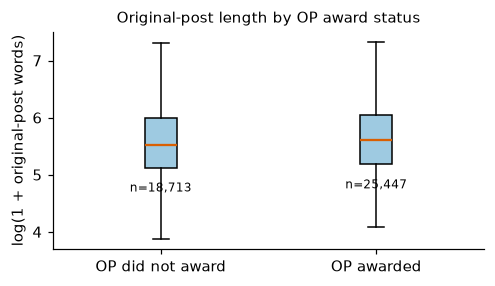

In [21]:
lp = np.log1p(THREADS.post_words)
a1, a0 = lp[THREADS.op_awarded], lp[~THREADS.op_awarded]
ft4 = f_test(a1, a0)
print(
    f"F-test: F = {ft4['F']:.3f}, df = ({ft4['df'][0]:,}, {ft4['df'][1]:,}), p = {fmt_p(ft4['p'])} -> "
    f"{'variances differ: use Welch' if ft4['p'] < ALPHA else 'no evidence variances differ'}"
)
t4 = welch_t(a1, a0)
p4 = 2 * stats.t.sf(abs(t4["t"]), t4["df"])
r4 = np.exp([t4["est"], *t4["ci"]])
print(
    f"awarded: {len(a1):,} threads, median {THREADS.post_words[THREADS.op_awarded].median():.0f} words;  "
    f"not: {len(a0):,}, median {THREADS.post_words[~THREADS.op_awarded].median():.0f} words"
)
print(
    f"ratio of (geometric) mean post length = {r4[0]:.3f}, 95% CI [{r4[1]:.3f}, {r4[2]:.3f}]"
)
print(
    f"Welch t = {t4['t']:.2f}, df = {t4['df']:,.0f}, two-sided p = {fmt_p(p4)} -> {'reject H0' if p4 < ALPHA else 'fail to reject H0'}"
)
print(f"meaningful (CI outside [1/1.20, 1.20]): {r4[1] > 1.2 or r4[2] < 1/1.2}")
pt4 = pooled_t(a1, a0)
print(f"\npooled t (for comparison): t = {pt4['t']:.2f}, df = {pt4['df']:,}")
long_ = THREADS.post_words > THREADS.post_words.median()
z4 = two_prop_z(
    THREADS.op_awarded[long_].sum(),
    long_.sum(),
    THREADS.op_awarded[~long_].sum(),
    (~long_).sum(),
)
print(
    f"two-proportion z, award rate for posts above vs below the median length: {z4['p1']:.1%} vs {z4['p2']:.1%}, z = {z4['z']:.1f}"
)
# Test 4 visual: compare full post-length distributions on the analysis scale.
fig, ax = plt.subplots(figsize=(4.6, 2.7))
ax.boxplot(
    [a0, a1],
    tick_labels=["OP did not award", "OP awarded"],
    showfliers=False,
    patch_artist=True,
    boxprops={"facecolor": "#9ecae1"},
    medianprops={"color": "#d95f02", "linewidth": 1.5},
)
ax.set_ylabel("log(1 + original-post words)")
ax.set_title("Original-post length by OP award status", fontsize=10)
ax.text(1, np.percentile(a0, 5), f"n={len(a0):,}", ha="center", va="bottom", fontsize=8)
ax.text(2, np.percentile(a1, 5), f"n={len(a1):,}", ha="center", va="bottom", fontsize=8)
fig.tight_layout()
fig.savefig(FIG_DIR / "post_length_award.png", dpi=220)
plt.show()


---
## 7. Summary

The conclusions below describe observed associations in the filtered 2017-2022 population. They should not be interpreted as causal effects or automatically generalized to excluded threads or later CMV activity.

In [22]:
summary = pd.DataFrame(
    [
        [
            "1 Length, within thread",
            "paired t",
            f"{t1['t']:.1f} ({t1['df']:,})",
            fmt_p(p1),
            f"{ratio[0]:.2f}x [{ratio[1]:.2f}, {ratio[2]:.2f}]",
            ratio[1] > 1.2,
        ],
        [
            "2 First 3 hours",
            "2-prop z",
            f"{t2['z']:.1f}",
            fmt_p(p2),
            f"+{100*t2['est']:.1f} pts [{100*t2['ci'][0]:.1f}, {100*t2['ci'][1]:.1f}]",
            t2["ci"][0] > 0.02,
        ],
        [
            "3 Has a link",
            "2-prop z",
            f"{t3['z']:.1f}",
            fmt_p(p3),
            f"+{100*t3['est']:.1f} pts [{100*t3['ci'][0]:.1f}, {100*t3['ci'][1]:.1f}]",
            t3["ci"][0] > 0.02,
        ],
        [
            "4 OP post length",
            "Welch t",
            f"{t4['t']:.1f} ({t4['df']:,.0f})",
            fmt_p(p4),
            f"{r4[0]:.3f}x [{r4[1]:.3f}, {r4[2]:.3f}]",
            r4[1] > 1.2 or r4[2] < 1 / 1.2,
        ],
    ],
    columns=[
        "test",
        "method",
        "statistic (df)",
        "p-value",
        "estimate [95% CI]",
        "matters?",
    ],
)
summary["decision"] = [
    "reject H0" if float(p.replace("< ", "")) < ALPHA else "fail to reject"
    for p in summary["p-value"]
]
summary.style.hide(axis="index")


test,method,statistic (df),p-value,estimate [95% CI],matters?,decision
"1 Length, within thread",paired t,"98.4 (23,054)",< 1e-300,"1.68x [1.66, 1.70]",True,reject H0
2 First 3 hours,2-prop z,153.5,< 1e-300,"+12.6 pts [12.4, 12.8]",True,reject H0
3 Has a link,2-prop z,60.4,< 1e-300,"+10.3 pts [9.8, 10.7]",True,reject H0
4 OP post length,Welch t,"11.0 (39,789)",4.52e-28,"1.068x [1.056, 1.081]",False,reject H0


### Main findings

1. **Reply length:** within the same thread, winning replies are estimated to be about 1.68 times as long as other retained replies. The confidence interval exceeds the 1.20 practical threshold.
2. **Response timing:** replies posted within 3 hours have a substantially higher observed win rate than later replies. The direction is also supported by a thread-level paired comparison.
3. **URL presence:** replies containing a URL have a higher observed win rate, including within each reply-length quartile. URL presence does not establish evidence quality, and residual confounding may remain.
4. **Original-post length:** OPs who award a delta write posts estimated to be about 1.07 times as long. The difference is statistically clear but remains below the 1.20 practical threshold.

The results are limited by observational design, within-thread dependence, reconstructed public outcomes, selection of intact and awarding threads, the 10-token reply threshold, and the April 2017-November 2022 analysis window.